# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

Q1. What is CLIP?
CLIP (Contrastive Language-Image Pre-training) is a model that learns to associate images with text by mapping them into a shared representation space.
Q2. What are its two main components?
An image encoder and a text encoder.
Q3. What is the role of  CLIPProcessor?
It prepares images and text for the model. It processes images and tokenizes text into the format required by CLIP.
Q4. What is the role of CLIPModel?
It encodes images and text and calculates similarity scores between them.


In [1]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [3]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

Image size: (500, 500)
Image mode: RGB


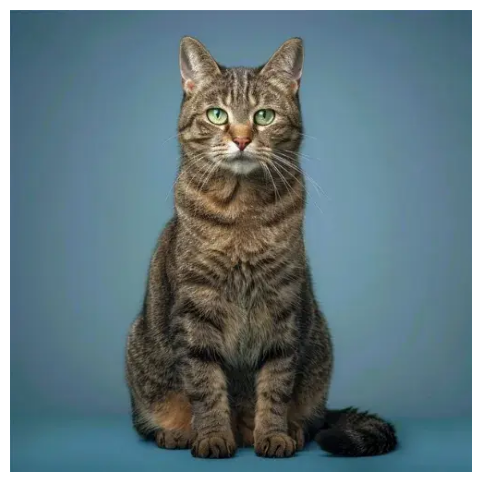

In [4]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "/content/chat.png.webp"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

Q5. The image size is 500 × 500 pixels (width × height).
Q6. The PIL image object contains pixel data in RGB format (red, green, ans blue channels).


## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

In [5]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9855
a photo of a dog                   : 0.0064
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0004
a photo of a person                : 0.0076


Q7. The discription "a photo of a cat" has the highest pobability (0.9855).
Q8. Yes. It is compatible with the actual image, which is a cat.
Q9. CLIP can compare images and sentences because its image and text encoders map them into a shared embedding space, where their similarity can be calculated.
Q10. softmax() converts raw scores into normalized values that sum to 1 across the candidate descriptions, making them easier to compare.

## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

Q11. Zero-shot classification means classifying an image into candidate classes without training a new classifier specifically for that task.
Q12. CLIP has already learned to align image and text representation during pretraining, so it can compare the image with text descriptions of the candidate classes.
Q13. If the correct class is not included, CLIP must choose the most similar class among the available candidates, so its prediction may be incorrect.

In [8]:
def classify_image(image, classes):
    texts = []
    for class_name in classes:
        article = "an" if class_name.lower().startswith(("a", "e", "i", "o", "u")) else "a"
        texts.append(f"a photo of {article} {class_name}")

    inputs = processor(
        text=texts,
        images=image,
        return_tensors="pt",
        padding=True
    )
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = outputs.logits_per_image.softmax(dim=1)[0]
    best_index = probabilities.argmax().item()

    return classes[best_index], probabilities[best_index].item()


classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.9926855564117432


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [9]:
dataset = [
    ("/content/imagecat1.png", "cat"),
    ("/content/imagecat2.png", "cat"),
    ("/content/imagedog1.png", "dog"),
    ("/content/imagedog2.png", "dog"),
    ("/content/imagecar1.png", "car"),
    ("/content/imagecar2.png", "car"),
    ("/content/imageairplane1.png", "airplane"),
    ("/content/imageairplane2.png", "airplane"),
    ("/content/imagehorse1.png", "horse"),
    ("/content/imagehorse2.png", "horse"),
]

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

results = []

for image_path, actual_class in dataset:
    eval_image = Image.open(image_path).convert("RGB")
    prediction, probability = classify_image(eval_image, classes)

    results.append({
        "image": image_path.split("/")[-1],
        "actual_class": actual_class,
        "predicted_class": prediction,
        "probability": probability,
        "correct": prediction == actual_class
    })

results_df = pd.DataFrame(results)
display(results_df)

accuracy = results_df["correct"].mean()
print(f"Accuracy: {accuracy:.2%} ({results_df['correct'].sum()}/{len(results_df)})")

,image,actual_class,predicted_class,probability,correct
0,imagecat1.png,cat,cat,0.993300,True
1,imagecat2.png,cat,cat,0.996866,True
2,imagedog1.png,dog,dog,0.997021,True
3,imagedog2.png,dog,dog,0.995871,True
4,imagecar1.png,car,car,0.992275,True
5,imagecar2.png,car,car,0.989969,True
6,imageairplane1.png,airplane,airplane,0.930294,True
7,imageairplane2.png,airplane,airplane,0.980424,True
8,imagehorse1.png,horse,horse,0.999543,True
9,imagehorse2.png,horse,horse,0.999682,True


Accuracy: 100.00% (10/10)


Q14. The obtained accuracy si 100% (10 out of 10 images).
Q15. No images were incorrectly classified in this dataset.
Q16. Possible reasons for classification errors include low image quality, poor lighting, or an object being partially hidden. Errors can also occur when an image is ambiguous or when the correct class is missing from the candidate classes.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

In [10]:
# STUDENT TASK
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

prompt_scores = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for prompt, score in zip(prompts, prompt_scores):
    print(f"{prompt:40s}: {score.item():.4f}")

a cat                                   : 0.0433
a photo of a cat                        : 0.4204
a photograph showing a cat              : 0.3680
an image containing a cat               : 0.1212
a domestic animal called a cat          : 0.0472


Q17. No, the scores are not identical; they vary depending on the prompt wording.
Q18. "A photo of a cat" gives the highest score (0.4204).
Q19. This demonstrates that prompt formulation affects CLIP's text representations and similarity scores, even when the prompts describe the same subject.

# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

In [11]:
from pathlib import Path
from shutil import copy2

IMAGE_DIR = Path("/content/images")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

for file_path in Path("/content").iterdir():
    if file_path.is_file() and file_path.suffix.lower() in {
        ".png", ".jpg", ".jpeg", ".webp"
    }:
        copy2(file_path, IMAGE_DIR / file_path.name)

print("Images dans le dossier :", len(list(IMAGE_DIR.iterdir())))

Images dans le dossier : 21


In [15]:
from pathlib import Path

IMAGE_DIR = Path("/content/images")
image_paths = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {
        ".png", ".jpg", ".jpeg", ".webp"
    }
)

image_names = []
embedding_list = []

for path in image_paths:
    img = Image.open(path).convert("RGB")
    pixel_values = processor(
        images=img, return_tensors="pt"
    )["pixel_values"].to(device)

    with torch.no_grad():
        image_features = model.get_image_features(
            pixel_values=pixel_values
        )

    if hasattr(image_features, "pooler_output"):
        image_features = image_features.pooler_output
    elif isinstance(image_features, tuple):
        image_features = image_features[0]

    embedding = torch.nn.functional.normalize(
        image_features, p=2, dim=-1
    )
    embedding_list.append(embedding.cpu())
    image_names.append(path.name)

image_embeddings = torch.cat(embedding_list, dim=0)

torch.save(
    {
        "image_names": image_names,
        "image_embeddings": image_embeddings
    },
    "/content/clip_image_embeddings.pt"
)

print("Images traitées :", len(image_names))
print("Forme des embeddings :", tuple(image_embeddings.shape))
print("Norme du premier embedding :", image_embeddings[0].norm().item())

Images traitées : 21
Forme des embeddings : (21, 512)
Norme du premier embedding : 0.9999999403953552


In [17]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.
# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.

IMAGE_DIR = "images"
QUERY = "a person playing football"
text_inputs = processor(
    text=[QUERY],
    return_tensors="pt",
    padding=True
)
text_inputs = {
    key: value.to(device)
    for key, value in text_inputs.items()
}

with torch.no_grad():
    text_features = model.get_text_features(**text_inputs)

if hasattr(text_features, "pooler_output"):
    text_features = text_features.pooler_output
elif isinstance(text_features, tuple):
    text_features = text_features[0]

query_embedding = torch.nn.functional.normalize(
    text_features, p=2, dim=-1
).cpu()

print("Forme de la requête :", tuple(query_embedding.shape))
print("Norme :", query_embedding.norm().item())

Forme de la requête : (1, 512)
Norme : 1.0


1. football3.png : 0.2774
2. football4.jpg : 0.2754
3. football2.jpg : 0.2752
4. football1.jpg : 0.2739
5. football5.jpg : 0.2480


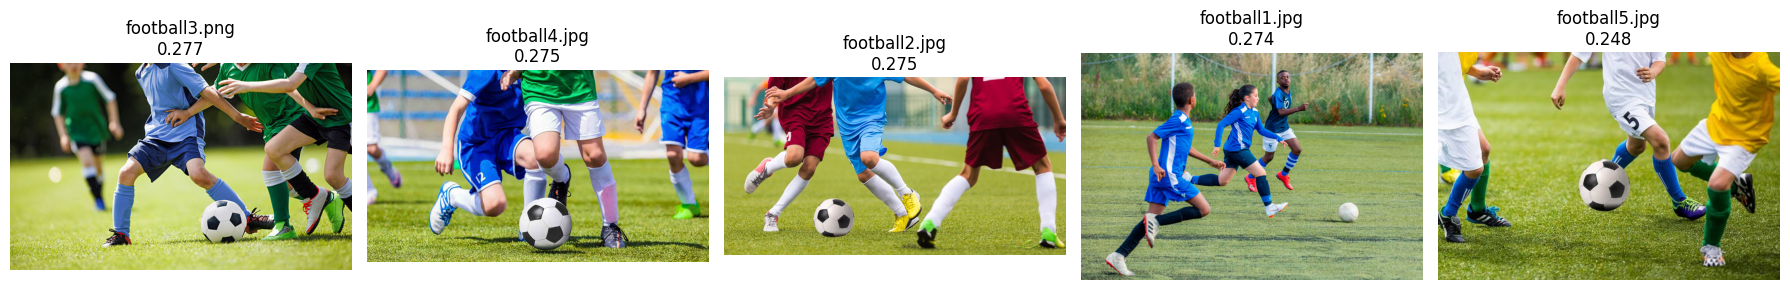

In [18]:
from pathlib import Path

similarities = (image_embeddings @ query_embedding.T).squeeze(1)
top_scores, top_indices = torch.topk(similarities, k=5)

for rank, (index, score) in enumerate(
    zip(top_indices, top_scores), start=1
):
    print(f"{rank}. {image_names[index.item()]} : {score.item():.4f}")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, index, score in zip(axes, top_indices, top_scores):
    index = index.item()
    img = Image.open(
        Path(IMAGE_DIR) / image_names[index]
    ).convert("RGB")

    ax.imshow(img)
    ax.set_title(f"{image_names[index]}\n{score.item():.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Q20. The most similar image is football3.png, with a cosine similarity score of 0.2774.
Q21. Yes. The image is semantically relevant because it shows people playing football.
Q22. Image labels are not needed because CLIP maps images and text into a shared semantic space and ranks images by their similarity to the query.
Q23. A real-world application is searching a large photo library using natural-language queries, such as finding images of people playing football.

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

Image → CLIP Vision Encoder → Projection Layer → Language Model → Text Response


Q24. The vision encoder extracts visual features from the image.
Q25. The projection layer maps the visual features into the representation space expected by the language model.
Q26. The language model uses the visual features and the prompt to generate a text response.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [2]:
from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
llava = LlavaOnevisionForConditionalGeneration.from_pretrained(MODEL_ID)

print("LLaVA est chargé.")
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

# STUDENT TASK
# from transformers import AutoProcessor, LlavaForConditionalGeneration
#
# MODEL_ID = "YOUR_LLAVA_CHECKPOINT"
# processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
# llava = LlavaForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )

processor_config.json:   0%|          | 0.00/178 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/1.73k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.59k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.79GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/716 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/126 [00:00<?, ?B/s]

LLaVA est chargé.


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

In [5]:
from google.colab import files
from pathlib import Path
from shutil import move

uploaded = files.upload()

image_dir = Path("/content/images")
image_dir.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    move(str(Path("/content") / filename), str(image_dir / filename))

print("Images chargées :", sorted(p.name for p in image_dir.iterdir()))

Saving food1.jpg to food1.jpg
Saving landscape1.jpg to landscape1.jpg
Saving building1.png to building1.png
Saving football3.png to football3.png
Saving chat.png.webp to chat.png.webp
Images chargées : ['building1.png', 'chat.png.webp', 'food1.jpg', 'football3.png', 'landscape1.jpg']


In [6]:
import re
import torch
import pandas as pd
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
llava.to(device)
llava.eval()
print("Appareil utilisé :", device)

def ask_five_questions(image_path, questions):
    image_vqa = Image.open(image_path).convert("RGB")

    prompt_text = (
        "Answer each question briefly. Return exactly five lines, "
        "numbered 1. to 5., one answer per line. "
        "If you cannot tell from the image, say so.\n\n"
    )
    prompt_text += "\n".join(
        f"{i}. {question}" for i, question in enumerate(questions, start=1)
    )

    conversation = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": prompt_text},
        ],
    }]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        text=prompt,
        images=image_vqa,
        return_tensors="pt"
    ).to(device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False
        )

    answer_tokens = output[:, inputs["input_ids"].shape[1]:]
    return processor_llava.batch_decode(
        answer_tokens,
        skip_special_tokens=True
    )[0].strip()


dataset_vqa = [
    {
        "image": "football3.png",
        "questions": [
            "What sport is shown?",
            "What are the players doing?",
            "What object are they using?",
            "How many players are visible?",
            "What colors are visible on their clothes?"
        ]
    },
    {
        "image": "chat.png.webp",
        "questions": [
            "What animal is shown?",
            "What color is its fur?",
            "What color are its eyes?",
            "What is the animal doing?",
            "What is visible in the background?"
        ]
    },
    {
        "image": "food1.jpg",
        "questions": [
            "What food is shown?",
            "What colors are visible in the food?",
            "What is the food served on?",
            "Are any utensils visible?",
            "What else can be seen in the image?"
        ]
    },
    {
        "image": "building1.png",
        "questions": [
            "What kind of structure is shown?",
            "What color is the structure?",
            "Is the scene indoors or outdoors?",
            "What can be seen around the structure?",
            "What is visible in the sky?"
        ]
    },
    {
        "image": "landscape1.jpg",
        "questions": [
            "What natural features are visible?",
            "Is there any water in the image?",
            "What color is the sky?",
            "What colors are most noticeable?",
            "What does the weather appear to be like?"
        ]
    }
]

rows = []

for item in dataset_vqa:
    image_path = f"/content/images/{item['image']}"
    answer_text = ask_five_questions(image_path, item["questions"])

    print(f"\nRéponses pour {item['image']} :\n{answer_text}")

    answers_by_number = {}
    for line in answer_text.splitlines():
        match = re.match(r"^\s*\**([1-5])[.):]\s*(.*)", line)
        if match:
            answers_by_number[int(match.group(1))] = match.group(2).strip()

    for i, question in enumerate(item["questions"], start=1):
        rows.append({
            "Image": item["image"],
            "Question": question,
            "LLaVA Answer": answers_by_number.get(
                i, "Voir les réponses groupées affichées au-dessus"
            ),
            "Human Evaluation": ""
        })

results_vqa_df = pd.DataFrame(rows)
display(results_vqa_df)

Appareil utilisé : cuda

Réponses pour football3.png :
1. Soccer
2. The players are playing soccer.
3. They are using a soccer ball.
4. There are three players visible.
5. The players are wearing blue and green shirts.

Réponses pour chat.png.webp :
1. The animal is a cat.
2. The fur is brown and gray.
3. The animal has green eyes.
4. The animal is sitting.
5. The background is blue.

Réponses pour food1.jpg :
1. The food is a bowl of rice with various vegetables and meat.
2. The colors visible in the food are red, yellow, green, and white.
3. The food is served on a plate.
4. Yes, there are utensils visible.
5. The image also shows a blue cloth and a small plate with chopped green onions.

Réponses pour building1.png :
1. The structure is a multi-story building.
2. The structure is white.
3. The scene is outdoors.
4. There are trees around the structure.
5. The sky is visible in the background.

Réponses pour landscape1.jpg :
1. The image shows a mountain range with snow-capped peaks.

,Image,Question,LLaVA Answer,Human Evaluation
0,football3.png,What sport is shown?,Soccer,
1,football3.png,What are the players doing?,The players are playing soccer.,
2,football3.png,What object are they using?,They are using a soccer ball.,
3,football3.png,How many players are visible?,There are three players visible.,
4,football3.png,What colors are visible on their clothes?,The players are wearing blue and green shirts.,
5,chat.png.webp,What animal is shown?,The animal is a cat.,
6,chat.png.webp,What color is its fur?,The fur is brown and gray.,
7,chat.png.webp,What color are its eyes?,The animal has green eyes.,
8,chat.png.webp,What is the animal doing?,The animal is sitting.,
9,chat.png.webp,What is visible in the background?,The background is blue.,


In [7]:
results_vqa_df["Human Evaluation"] = "Correct"

correct_answers = results_vqa_df["Human Evaluation"].eq("Correct").sum()
total_questions = len(results_vqa_df)
vqa_accuracy = correct_answers / total_questions

display(results_vqa_df)
print(f"VQA Accuracy: {vqa_accuracy:.2%} ({correct_answers}/{total_questions})")

,Image,Question,LLaVA Answer,Human Evaluation
0,football3.png,What sport is shown?,Soccer,Correct
1,football3.png,What are the players doing?,The players are playing soccer.,Correct
2,football3.png,What object are they using?,They are using a soccer ball.,Correct
3,football3.png,How many players are visible?,There are three players visible.,Correct
4,football3.png,What colors are visible on their clothes?,The players are wearing blue and green shirts.,Correct
5,chat.png.webp,What animal is shown?,The animal is a cat.,Correct
6,chat.png.webp,What color is its fur?,The fur is brown and gray.,Correct
7,chat.png.webp,What color are its eyes?,The animal has green eyes.,Correct
8,chat.png.webp,What is the animal doing?,The animal is sitting.,Correct
9,chat.png.webp,What is visible in the background?,The background is blue.,Correct


VQA Accuracy: 100.00% (25/25)


Q27. The VQA accuracy is 100% (25/25).
Q28. LLaVA can struggle with counting people or objects, identifying small or partially hidden details, understanding spatial relationships, and reading text in images. It may sometimes miss details or give a plausible but incorrect answer.


## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

In [8]:
from PIL import Image
import torch

image_path = "/content/images/chat.png.webp"
image_vqa = Image.open(image_path).convert("RGB")

def ask_one_question(image, question):
    conversation = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=50,
            do_sample=False
        )

    answer_tokens = output[:, inputs["input_ids"].shape[1]:]
    return processor_llava.batch_decode(
        answer_tokens,
        skip_special_tokens=True
    )[0].strip()


questions = [
    "Is there a bicycle in this image?",
    "What color is the bicycle?",
    "Where is the bicycle located?"
]

for question in questions:
    print("Question:", question)
    print("LLaVA answer:", ask_one_question(image_vqa, question))
    print()

Question: Is there a bicycle in this image?
LLaVA answer: no

Question: What color is the bicycle?
LLaVA answer: The bicycle in the image is not visible. The image shows a cat with a striped pattern, but it does not depict a bicycle.

Question: Where is the bicycle located?
LLaVA answer: The bicycle is located on the sidewalk, near the street.



Q29. No, there is no bicycle in the image.
Q30. Yes. LLaVA invented a location for the bicycle in its third answer.
Q31. A visual hallucination occurs when a model describes an object or detail that is not actually present in the image.
Q32. A multimodal model can rely on learned language patterns instead of the image evidence. The question assumes there is a bicycle, which may lead the model to invent a plausible location.

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

In [9]:
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(device)
clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)
clip_model.eval()

image_compare = Image.open(
    "/content/images/chat.png.webp"
).convert("RGB")

descriptions = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a horse"
]

inputs = clip_processor(
    text=descriptions,
    images=image_compare,
    return_tensors="pt",
    padding=True
).to(device)

with torch.inference_mode():
    outputs = clip_model(**inputs)

probabilities = outputs.logits_per_image.softmax(dim=1)[0]

for description, probability in zip(descriptions, probabilities):
    print(f"{description}: {probability.item():.4f}")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

a photo of a cat: 0.9931
a photo of a dog: 0.0064
a photo of a horse: 0.0004


In [10]:
question = "What animal is present in the image? Describe its appearance."
answer = ask_one_question(image_compare, question)

print("LLaVA answer:", answer)

LLaVA answer: A cat is present in the image. It has a striped coat with shades of brown and black, and its eyes are a striking green color.


Q33. CLIP is better suited to image classification because it compares an image with candidate class descriptions and ranks them by similarity.
Q34. LLaVA is better for image description because it generates natural-language text about the image.
Q35. LLaVA is better for visual question answering because it can answer questions about image content in natural language.
Q36. CLIP compares image and text representations in a shared embedding space. LLaVA combines visual information with a language model to generate answers and descriptions.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

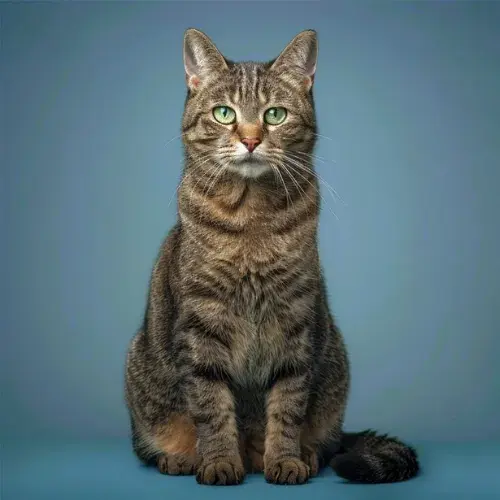

Question: What animal is present in the image? Describe its appearance.
Assistant answer: A cat is present in the image. It has a striped coat with shades of brown and black, and its eyes are a striking green color.


In [11]:
from PIL import Image
import torch

def multimodal_image_assistant(image_path, question):
    image = Image.open(image_path).convert("RGB")

    conversation = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": question}
        ]
    }]

    prompt = processor_llava.apply_chat_template(
        conversation,
        add_generation_prompt=True
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to(llava.device)

    with torch.inference_mode():
        output = llava.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    answer_tokens = output[:, inputs["input_ids"].shape[1]:]
    answer = processor_llava.batch_decode(
        answer_tokens,
        skip_special_tokens=True
    )[0].strip()

    return answer


image_path = "/content/images/chat.png.webp"
question = "What animal is present in the image? Describe its appearance."

image = Image.open(image_path).convert("RGB")
display(image)
print("Question:", question)
print("Assistant answer:", multimodal_image_assistant(image_path, question))

In [12]:
from pathlib import Path
from PIL import Image
import torch

image_dir = Path("/content/images")
image_paths = sorted(
    path for path in image_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)
images = [Image.open(path).convert("RGB") for path in image_paths]

query = "a person playing football"

inputs = clip_processor(
    text=[query],
    images=images,
    return_tensors="pt",
    padding=True
).to(device)

with torch.inference_mode():
    outputs = clip_model(**inputs)

scores = outputs.logits_per_image[:, 0].softmax(dim=0)
top_indices = scores.argsort(descending=True)[:5]

top_paths = []

print("Top-5 images pour la requête :", query)
for rank, index in enumerate(top_indices, start=1):
    i = index.item()
    top_paths.append(image_paths[i])
    print(f"{rank}. {image_paths[i].name} : {scores[i].item():.4f}")

best_image_path = str(top_paths[0])
question = f"Describe this image and explain whether it matches this query: {query}"

print("\nExplication de LLaVA :")
print(multimodal_image_assistant(best_image_path, question))

Top-5 images pour la requête : a person playing football
1. football3.png : 0.9999
2. chat.png.webp : 0.0001
3. landscape1.jpg : 0.0000
4. building1.png : 0.0000
5. food1.jpg : 0.0000

Explication de LLaVA :
The image depicts a group of young children playing football on a grassy field. The children are wearing sports uniforms, with one team in blue and the other in green. The focus is on a child in the foreground who is actively kicking a black and white soccer ball. The children appear to be engaged in a competitive match, with one player in blue attempting to gain possession of the ball.


Conclusion: CLIP is useful for zero-shot classification and image retrieval by comparing image and text representations. LLaVA can describe images and answer visual questions in natural language. The hallucination experiment showed that LLaVA can invent details, so its answers should be checked against the image.
